# Actividad grupal clase 5 — Regresión clásica y regularizada

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

**Integrantes del grupo:** _(listar aquí a los integrantes)_

Contenido:
1. Miniexploración a mano: la recta de cuatro tiendas, su $R^2$ y el encogimiento de Ridge
2. Consumo eléctrico con `statsmodels`
3. ¿Ayuda regularizar? OLS, Ridge, Lasso y Elastic Net
4. La fuga de datos en vivo
5. Reflexión

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.api import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

---
## Parte 1: Miniexploración a mano

Una cadena de cuatro tiendas registró su inversión en publicidad del mes ($x$, en cientos de miles de colones) y sus ventas ($y$, en millones de colones):

| Tienda | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| $x$ (publicidad) | 1 | 2 | 3 | 4 |
| $y$ (ventas) | 3 | 5 | 6 | 8 |

### 1.1 La recta de mínimos cuadrados

| $i$ | $x_i$ | $y_i$ | $x_i-\bar x$ | $y_i-\bar y$ | $(x_i-\bar x)(y_i-\bar y)$ | $(x_i-\bar x)^2$ |
|---|---|---|---|---|---|---|
| 1 | 1 | 3 | −1.5 | −2.5 | 3.75 | 2.25 |
| 2 | 2 | 5 | −0.5 | −0.5 | 0.25 | 0.25 |
| 3 | 3 | 6 | 0.5 | 0.5 | 0.25 | 0.25 |
| 4 | 4 | 8 | 1.5 | 2.5 | 3.75 | 2.25 |
| Suma | 10 | 22 | | | $S_{xy}=8$ | $S_{xx}=5$ |

$$\bar x=\frac{10}{4}=2.5,\quad \bar y=\frac{22}{4}=5.5,\quad \hat\beta_1=\frac{S_{xy}}{S_{xx}}=\frac{8}{5}=1.6,\quad \hat\beta_0=\bar y-\hat\beta_1\bar x=5.5-1.6(2.5)=1.5$$

La recta es $\hat y=1.5+1.6\,x$.

### 1.2 Interpretación de la pendiente

Cada **cien mil colones adicionales de publicidad** en el mes se asocian con **1.6 millones de colones más de ventas**, en promedio. (Es una asociación entre tiendas, no necesariamente un efecto causal.) El intercepto, 1.5 millones, sería la venta esperada sin publicidad, y solo es interpretable si $x=0$ está dentro del rango observado (aquí no lo está: $x$ va de 1 a 4).

### 1.3 Predicciones, residuos, RSS, TSS y $R^2$

| $x_i$ | $y_i$ | $\hat y_i=1.5+1.6x_i$ | $e_i=y_i-\hat y_i$ | $e_i^2$ | $(y_i-\bar y)^2$ |
|---|---|---|---|---|---|
| 1 | 3 | 3.1 | −0.1 | 0.01 | 6.25 |
| 2 | 5 | 4.7 | 0.3 | 0.09 | 0.25 |
| 3 | 6 | 6.3 | −0.3 | 0.09 | 0.25 |
| 4 | 8 | 7.9 | 0.1 | 0.01 | 6.25 |
| Suma | | | 0 | **RSS = 0.2** | **TSS = 13** |

$$R^2=1-\frac{\text{RSS}}{\text{TSS}}=1-\frac{0.2}{13}\approx\mathbf{0.985}$$

La publicidad "explica" el 98.5 % de la variación de las ventas entre estas cuatro tiendas. (Los residuos suman 0, como siempre que hay intercepto.)

### 1.4 Ridge

$$\hat\beta_1^{\text{ridge}}=\frac{S_{xy}}{S_{xx}+\lambda}$$

| $\lambda$ | 0 (OLS) | 1 | 5 | 15 |
|---|---|---|---|---|
| $\hat\beta_1$ | 1.60 | $8/6=$ **1.33** | $8/10=$ **0.80** | $8/20=$ **0.40** |

**¿Qué pasa con la pendiente?** Se **encoge hacia 0** a medida que crece $\lambda$ (con $\lambda\to\infty$ el modelo tiende a predecir siempre $\bar y$), pero nunca llega exactamente a 0: Ridge **contrae** los coeficientes, no los anula (eso lo hace Lasso). El precio es **sesgo** (la pendiente ya no es la de mínimos cuadrados) y el beneficio es menor **varianza**; la penalización solo conviene si el balance mejora el error fuera de muestra.

x̄=2.5, ȳ=5.5, Sxy=8.0, Sxx=5.0 -> b1=1.6, b0=1.5
predicciones: [3.1 4.7 6.3 7.9] | residuos: [-0.1  0.3 -0.3  0.1]
RSS=0.20, TSS=13, R2=0.9846
lambda= 0: pendiente Ridge = 1.60
lambda= 1: pendiente Ridge = 1.33
lambda= 5: pendiente Ridge = 0.80
lambda=15: pendiente Ridge = 0.40


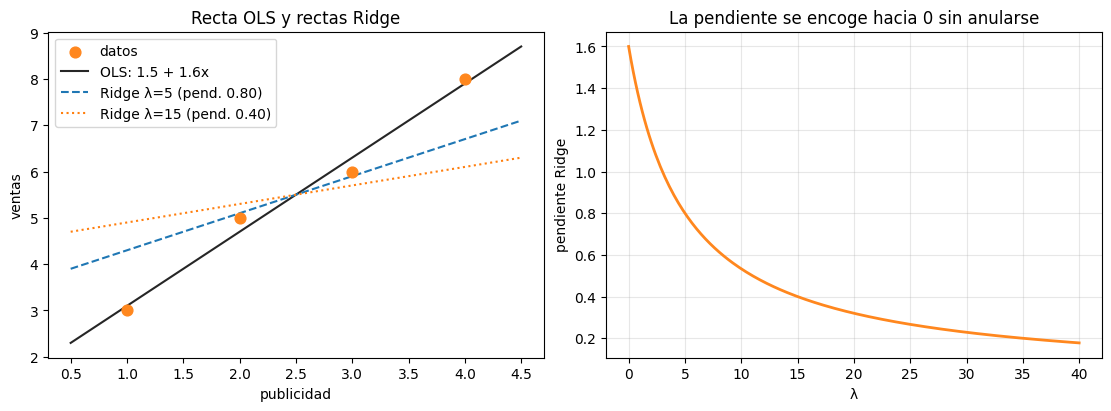

In [2]:
# Verificación en código de la parte 1
x = np.array([1, 2, 3, 4.]); y = np.array([3, 5, 6, 8.])
xb, yb = x.mean(), y.mean()
Sxy = np.sum((x - xb) * (y - yb)); Sxx = np.sum((x - xb)**2)
b1 = Sxy / Sxx; b0 = yb - b1 * xb
yhat = b0 + b1 * x; e = y - yhat
RSS = np.sum(e**2); TSS = np.sum((y - yb)**2)
print(f"x̄={xb}, ȳ={yb}, Sxy={Sxy}, Sxx={Sxx} -> b1={b1}, b0={b0}")
print("predicciones:", yhat.round(2), "| residuos:", e.round(2))
print(f"RSS={RSS:.2f}, TSS={TSS:.0f}, R2={1 - RSS/TSS:.4f}")
for lam in [0, 1, 5, 15]:
    print(f"lambda={lam:2d}: pendiente Ridge = {Sxy/(Sxx + lam):.2f}")

lams = np.linspace(0, 40, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
ax[0].scatter(x, y, color="#FF871E", s=60, zorder=3, label="datos")
xs = np.linspace(0.5, 4.5, 50); ax[0].plot(xs, b0 + b1 * xs, color="#262626", label=f"OLS: {b0:.1f} + {b1:.1f}x")
for lam, ls in [(5, "--"), (15, ":")]:
    bl = Sxy / (Sxx + lam); ax[0].plot(xs, yb + bl * (xs - xb), ls=ls, label=f"Ridge λ={lam} (pend. {bl:.2f})")
ax[0].set(xlabel="publicidad", ylabel="ventas", title="Recta OLS y rectas Ridge"); ax[0].legend()
ax[1].plot(lams, Sxy / (Sxx + lams), color="#FF871E", lw=2)
ax[1].set(xlabel="λ", ylabel="pendiente Ridge", title="La pendiente se encoge hacia 0 sin anularse"); ax[1].grid(alpha=0.3)
plt.show()

---
## Parte 2: Consumo eléctrico con `statsmodels`

Se simulan 400 hogares. La "verdad" con que se construyó el consumo: **35 kWh por persona, 0.8 por metro cuadrado, 70 por tener aire acondicionado y 3 por grado de temperatura media**, más ruido normal con desviación 30. Las habitaciones casi repiten la información de los metros cuadrados y hay seis variables de puro ruido.

In [3]:
rng = np.random.default_rng(2026)
n = 400
personas = rng.integers(1, 7, n).astype(float)
m2 = rng.normal(110, 35, n).clip(40, 300)
habitaciones = (m2 / 35 + rng.normal(0, 0.4, n)).round().clip(1, 7)
aire = (rng.random(n) < 0.3).astype(float)
temp = rng.normal(25, 3, n)
ruidos = rng.normal(0, 1, (n, 6))
kwh = 60 + 35*personas + 0.8*m2 + 70*aire + 3*temp + rng.normal(0, 30, n)
df = pd.DataFrame({"kwh": kwh, "personas": personas, "m2": m2,
                   "habitaciones": habitaciones, "aire": aire, "temp": temp})
for j in range(6):
    df[f"ruido{j+1}"] = ruidos[:, j]
df.head()

,kwh,personas,m2,habitaciones,aire,temp,ruido1,ruido2,ruido3,ruido4,ruido5,ruido6
0,439.454870,6.0,129.505588,3.0,0.0,26.189368,0.822148,1.174723,-1.559761,-1.507620,-0.169988,1.944242
1,371.689189,2.0,114.020676,3.0,1.0,22.161444,-0.789894,0.493770,-1.658720,-0.917596,0.471725,-0.256900
2,244.176228,1.0,97.065624,3.0,0.0,27.203642,0.483355,0.106414,-0.033120,-0.055460,1.350078,-0.087803
3,376.837329,4.0,137.233452,4.0,0.0,24.379641,0.837304,-0.291130,0.065514,-1.100477,-2.126951,-0.455295
4,386.318587,3.0,119.299604,3.0,1.0,25.341665,0.064680,-0.512276,0.506691,-0.836846,-1.432332,-1.514558


In [4]:
mod = smf.ols("kwh ~ personas + m2 + aire + temp", data=df).fit()
print(mod.params.round(3))
# personas 33.469, m2 0.740, aire 67.144, temp 3.288
print(mod.conf_int().round(3))      # aire: 60.730 a 73.557
print(round(mod.rsquared, 3))       # 0.847

# ¿Los intervalos de 95 % contienen la verdad?
verdad = {"personas": 35, "m2": 0.8, "aire": 70, "temp": 3}
ci = mod.conf_int()
for var, v in verdad.items():
    lo, hi = ci.loc[var]
    print(f"{var:9s} verdad = {v:>5}: IC95 = ({lo:7.3f}, {hi:7.3f}) -> {'contiene' if lo <= v <= hi else 'NO contiene'}")

Intercept    66.640
personas     33.469
m2            0.740
aire         67.144
temp          3.288
dtype: float64
                0       1
Intercept  40.345  92.934
personas   31.713  35.225
m2          0.657   0.823
aire       60.730  73.557
temp        2.338   4.239
0.847
personas  verdad =    35: IC95 = ( 31.713,  35.225) -> contiene
m2        verdad =   0.8: IC95 = (  0.657,   0.823) -> contiene
aire      verdad =    70: IC95 = ( 60.730,  73.557) -> contiene
temp      verdad =     3: IC95 = (  2.338,   4.239) -> contiene


**2. Intervalos de 95 %.** Los cuatro intervalos **contienen el valor verdadero** (personas: 31.7–35.2 ∋ 35; m²: 0.657–0.823 ∋ 0.8; aire: 60.7–73.6 ∋ 70; temperatura: 2.3–4.2 ∋ 3). El modelo recupera bien los coeficientes, con $R^2=0.847$ (el ruido de desviación 30 limita el $R^2$ máximo posible).

**3. Coeficiente de `aire`.** Con el mismo número de personas, metros cuadrados y temperatura media, un hogar con aire acondicionado consume en promedio **unos 67 kWh más al mes** (IC 95 %: 61 a 74 kWh).

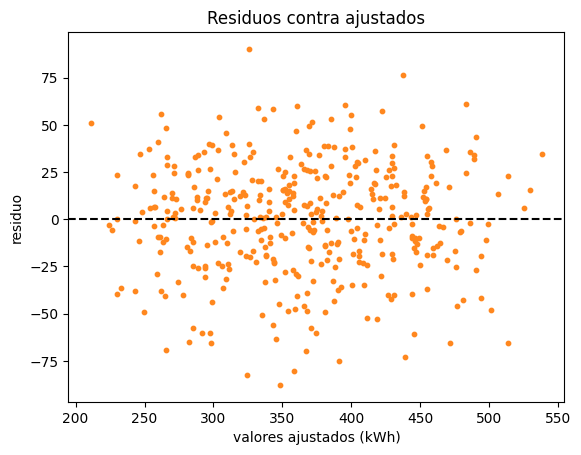

Breusch-Pagan, p-valor: 0.638


In [5]:
# Residuos contra ajustados y prueba de Breusch-Pagan
plt.scatter(mod.fittedvalues, mod.resid, s=10, color="#FF871E")
plt.axhline(0, color="black", ls="--")
plt.xlabel("valores ajustados (kWh)"); plt.ylabel("residuo"); plt.title("Residuos contra ajustados"); plt.show()

bp = het_breuschpagan(mod.resid, mod.model.exog)
print("Breusch-Pagan, p-valor:", round(bp[1], 3))      # 0.638

**4. Diagnóstico de residuos.** El gráfico no muestra patrón: los residuos se reparten alrededor de 0 con ancho constante (no hay embudo ni curvatura). Breusch-Pagan da $p=0.638$: **no hay evidencia de heterocedasticidad** (no se rechaza que la varianza sea constante), lo cual es coherente con cómo se simularon los datos.

### Pregunta para discutir: ¿por qué no incluimos `habitaciones`? Agréguenla y miren el error estándar de `m2`

In [6]:
mod_hab = smf.ols("kwh ~ personas + m2 + habitaciones + aire + temp", data=df).fit()
print(mod_hab.summary().tables[1])

print("\nerror estándar de m2 sin habitaciones:", round(mod.bse["m2"], 4))
print("error estándar de m2 con habitaciones:", round(mod_hab.bse["m2"], 4))
print("correlación m2 - habitaciones:", round(np.corrcoef(df.m2, df.habitaciones)[0, 1], 3))

# Factor de inflación de la varianza (VIF) de cada variable
Xv = mod_hab.model.exog
for nombre, i in zip(mod_hab.model.exog_names, range(Xv.shape[1])):
    if nombre != "Intercept":
        print(f"VIF {nombre:13s} {variance_inflation_factor(Xv, i):5.2f}")

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       66.4585     13.405      4.958      0.000      40.103      92.814
personas        33.4745      0.895     37.420      0.000      31.716      35.233
m2               0.7650      0.096      7.943      0.000       0.576       0.954
habitaciones    -0.8665      3.051     -0.284      0.777      -6.865       5.132
aire            67.1237      3.267     20.547      0.000      60.701      73.546
temp             3.2959      0.485      6.801      0.000       2.343       4.249

error estándar de m2 sin habitaciones: 0.0422
error estándar de m2 con habitaciones: 0.0963
correlación m2 - habitaciones: 0.899
VIF personas       1.01
VIF m2             5.22
VIF habitaciones   5.22
VIF aire           1.00
VIF temp           1.01


**Resultado.** Al agregar `habitaciones`, el error estándar de `m2` pasa de **0.042 a 0.096** (más del doble), el coeficiente de `m2` se mueve a 0.765 y el de `habitaciones` sale **−0.87 con error estándar de 3.05** (p = 0.78: no significativo; el valor verdadero es 0). La causa es la **multicolinealidad**: `habitaciones` se construyó casi como $m^2/35$, la correlación con `m2` es ≈ 0.90 y el VIF de ambas es ≈ 5.2. Las dos variables miden casi lo mismo, así que el modelo no puede decidir a cuál atribuir el efecto y los coeficientes individuales se vuelven **inestables** (intervalos más anchos). No se incluyó `habitaciones` porque no aporta información nueva y solo infla la varianza; las predicciones casi no cambian, pero la **interpretación** de cada coeficiente sí se deteriora. (Regularizar —Ridge, Lasso— es otra forma de manejar este problema.)

---
## Parte 3: ¿Ayuda regularizar?

Ahora se usan **las once variables**, incluidas `habitaciones` y los seis ruidos.

**1. Predicción antes de correr.** Esperábamos que Lasso o Elastic Net ganaran, por la presencia de variables de ruido y de la colineal `habitaciones` (OLS tendría más varianza), con Ridge en segundo lugar y OLS al final. Veamos si ocurre.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.model_selection import KFold, cross_val_score

X = df.drop(columns="kwh").values
y = df["kwh"].values
cv = KFold(n_splits=5, shuffle=True, random_state=42)
modelos = {"OLS": LinearRegression(),
           "Ridge": RidgeCV(alphas=np.logspace(-3, 3, 50)),
           "Lasso": LassoCV(cv=5, random_state=0),
           "ElasticNet": ElasticNetCV(l1_ratio=[.1, .5, .9, 1], cv=5,
                                      random_state=0)}
for nombre, est in modelos.items():
    pipe = make_pipeline(StandardScaler(), est)        # el escalado va dentro del Pipeline (sin fuga)
    rmse = -cross_val_score(pipe, X, y, cv=cv,
                            scoring="neg_root_mean_squared_error")
    print(f"{nombre:10s} RMSE CV = {rmse.mean():.2f}  (± {rmse.std():.2f} entre pliegues)")
# OLS 30.06 | Ridge 30.07 | Lasso 29.90 | ElasticNet 29.90

OLS        RMSE CV = 30.06  (± 2.44 entre pliegues)
Ridge      RMSE CV = 30.07  (± 2.42 entre pliegues)


Lasso      RMSE CV = 29.90  (± 2.39 entre pliegues)


ElasticNet RMSE CV = 29.90  (± 2.39 entre pliegues)


In [8]:
# Lasso con todos los datos: qué variables apagó (coeficientes en unidades estandarizadas)
lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0)).fit(X, y)
for nombre, c in zip(df.columns[1:], lasso[-1].coef_):
    print(f"{nombre:13s} {c:+.2f}" + ("   <- apagada (0 exacto)" if c == 0 else ""))
print("alpha elegido por validación cruzada:", round(lasso[-1].alpha_, 3))

personas      +54.86
m2            +25.27
habitaciones  +0.00   <- apagada (0 exacto)
aire          +29.67
temp          +9.06
ruido1        -0.29
ruido2        +0.00   <- apagada (0 exacto)
ruido3        -0.64
ruido4        -0.54
ruido5        +2.70
ruido6        -0.36
alpha elegido por validación cruzada: 0.895


**2. Resultado.** Los cuatro modelos quedan **prácticamente empatados** (RMSE entre 29.9 y 30.1 kWh, con variación entre pliegues de ±2.4), y todos cerca de 30, que es la desviación del ruido verdadero: ningún modelo puede bajar de ahí. Con 400 hogares y solo 11 variables, OLS ya no sobreajusta, así que regularizar casi no cambia la predicción. La predicción del grupo era incorrecta.

**3. Lasso apagó** `habitaciones` y `ruido2` (coeficientes exactamente 0). Dejó los otros cinco ruidos con coeficientes pequeños (el mayor, `ruido5` = +2.70, frente a 54.9 de `personas`, 29.7 de `aire`, 25.3 de `m2` y 9.1 de `temp`). Lasso elimina bien la colineal `habitaciones`, pero no siempre limpia todo el ruido: el α que minimiza el error de validación cruzada deja pasar algo de ruido.

### Pregunta: ¿en qué situación esperarían que la regularización sí gane con claridad?

Cuando hay **pocas observaciones frente al número de variables** ($p$ cercano o mayor que $n$) y/o **fuerte colinealidad**. Se prueba simulando el mismo proceso con menos hogares y muchas variables de ruido:

In [9]:
def simular(n, n_ruido, semilla=2026):
    # mismo proceso que arriba, con n hogares y n_ruido variables de ruido
    rng = np.random.default_rng(semilla)
    personas = rng.integers(1, 7, n).astype(float)
    m2 = rng.normal(110, 35, n).clip(40, 300)
    hab = (m2 / 35 + rng.normal(0, 0.4, n)).round().clip(1, 7)
    aire = (rng.random(n) < 0.3).astype(float)
    temp = rng.normal(25, 3, n)
    ruidos = rng.normal(0, 1, (n, n_ruido))
    kwh = 60 + 35*personas + 0.8*m2 + 70*aire + 3*temp + rng.normal(0, 30, n)
    return np.column_stack([personas, m2, hab, aire, temp, ruidos]), kwh

filas = []
for n_, r_ in [(400, 6), (100, 40), (80, 60)]:
    Xs, ys = simular(n_, r_)
    fila = {"n": n_, "p": Xs.shape[1]}
    for nombre, est in modelos.items():
        rmse = -cross_val_score(make_pipeline(StandardScaler(), est), Xs, ys, cv=cv,
                                scoring="neg_root_mean_squared_error")
        fila[nombre] = round(rmse.mean(), 1)
    filas.append(fila)
pd.DataFrame(filas).set_index(["n", "p"])

,,OLS,Ridge,Lasso,ElasticNet
n,p,,,,
400,11,30.1,30.1,29.9,29.9
100,45,37.6,37.3,32.1,32.1
80,65,104.1,51.3,34.7,34.7


**Lectura.** Con $n=400$, $p=11$ hay empate. Con $n=100$, $p=45$ Lasso y Elastic Net ya bajan el error de ~37.6 a ~32.1; y con $n=80$, $p=65$ la diferencia es enorme: **OLS ~104 kWh, Ridge ~51, Lasso/Elastic Net ~35**. OLS se dispara porque con $p$ casi igual a $n$ ajusta el ruido; Ridge estabiliza los coeficientes pero deja pasar todo el ruido, mientras que Lasso, al apagar variables, gana cuando hay **muchas variables irrelevantes** y pocos datos. Esa es la idea de la clase: la regularización paga cuando hay mucha varianza que reducir, y ahí también ayuda la selección de variables. (La simulación de la ENAHO de la clase, con colinealidad, es el otro caso favorable a Ridge.)

---
## Parte 4: La fuga de datos en vivo

100 filas, 1000 variables y una $y$, todo **ruido puro**: no hay nada que predecir.

In [10]:
from sklearn.feature_selection import SelectKBest, f_regression

rng2 = np.random.default_rng(2026)
Xr = rng2.normal(size=(100, 1000))
yr = rng2.normal(size=100)

# Tramposa: la selección ve todos los datos, incluidos los exámenes
Xmal = SelectKBest(f_regression, k=10).fit_transform(Xr, yr)
r2_mal = cross_val_score(LinearRegression(), Xmal, yr, cv=cv, scoring="r2")

# Honesta: la selección vive dentro del Pipeline
pipe_bien = make_pipeline(SelectKBest(f_regression, k=10), LinearRegression())
r2_bien = cross_val_score(pipe_bien, Xr, yr, cv=cv, scoring="r2")

print(f"R2 con fuga: {r2_mal.mean():.2f}")     # 0.26
print(f"R2 honesto:  {r2_bien.mean():.2f}")    # -0.78

R2 con fuga: 0.26
R2 honesto:  -0.78


In [11]:
# ¿Fue casualidad de esta semilla? Se repite con 30 semillas distintas
mal, bien = [], []
for s in range(30):
    r = np.random.default_rng(s)
    Xs, ys = r.normal(size=(100, 1000)), r.normal(size=100)
    mal.append(cross_val_score(LinearRegression(), SelectKBest(f_regression, k=10).fit_transform(Xs, ys), ys, cv=cv, scoring="r2").mean())
    bien.append(cross_val_score(make_pipeline(SelectKBest(f_regression, k=10), LinearRegression()), Xs, ys, cv=cv, scoring="r2").mean())
print(f"R2 con fuga  : media {np.mean(mal):.2f}  (mín {np.min(mal):.2f}, máx {np.max(mal):.2f})")
print(f"R2 honesto   : media {np.mean(bien):.2f}  (mín {np.min(bien):.2f}, máx {np.max(bien):.2f})")

R2 con fuga  : media 0.25  (mín 0.08, máx 0.44)
R2 honesto   : media -0.51  (mín -0.94, máx -0.16)


**Comparación.** Con fuga, el modelo "explica" el **26 %** de la variación de puro ruido; la validación honesta da $R^2=-0.78$, es decir, **peor que predecir siempre el promedio** (que es lo correcto, porque no hay nada que predecir). No es casualidad de la semilla: en 30 repeticiones el $R^2$ con fuga es positivo y el honesto es negativo.

**¿Por qué?** Con 1000 variables y 100 filas, alguna(s) variable(s) correlaciona(n) con $y$ por pura casualidad. Si la selección de las 10 "mejores" se hace con **todos** los datos, esas variables ya fueron elegidas mirando también las filas de validación, así que el examen "ya vio la respuesta". Dentro del Pipeline, la selección se rehace en cada pliegue **solo con el entrenamiento**, y el modelo seleccionado fracasa en las filas no vistas. La regla de oro: todo lo que se aprende de los datos (escalado, selección de variables, imputación, elección de hiperparámetros) se aprende solo con el entrenamiento.

---
## Parte 5: Reflexión

**Observación matemática.** Sorprende el empate de la parte 3: con 400 hogares y 11 variables, un OLS sin ninguna penalización predice igual que Ridge, Lasso y Elastic Net (RMSE ≈ 30 en todos, que es justo la desviación del ruido). La regularización no es una mejora automática; solo gana cuando hay varianza que reducir, y lo comprobamos con $n=80$, $p=65$, donde OLS llega a ~104 kWh de error y Lasso a ~35. La colinealidad (`habitaciones`) además infló el error estándar de `m2` más del doble sin que la predicción cambiara.

**Observación técnica.** La selección de variables va **dentro del Pipeline** porque debe aprenderse solo con los datos de entrenamiento de cada pliegue. Si se hace antes de la validación cruzada, los datos de validación influyen en qué variables se eligen (fuga de datos) y el $R^2$ de validación sale artificialmente alto (0.26 sobre ruido puro) en lugar de negativo (−0.78). Lo mismo aplica al `StandardScaler`: debe ajustarse con el entrenamiento de cada pliegue.

**Pregunta abierta.** En nuestro proyecto, ¿cuál sería la $y$ y cuáles las $x$? _(completar según el carril del grupo: variable a predecir, variables explicativas candidatas, cuántas observaciones hay —¿$n$ es grande frente a $p$?—, si hay variables muy correlacionadas entre sí y qué estrategia de validación corresponde: K-fold si las filas son independientes, o validación temporal si hay orden en el tiempo.)_